# Balance Checks & McCray Test

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdrobust import rdrobust
from rdrobust import rdbwselect
from rdrobust import rdplot
from rddensity import rddensity, rdplotdensity
import re

In [2]:
df_rdd = pd.read_csv('df_rdd_clean.csv')

In [3]:
df_rdd

,code_commune,nuance,voix,election_year,tour,is_far_right,treat,d_50,skill_share_pre,skill_share_trend,...,no_diploma_share,skill_share_trend2,far_right_participated,pop_growth,income_median,income_gini,unemployment_rate,foreign_population,share_55plus,share_15_24
0,1053,LUG,437,2014,t1,False,0,-2.409639,0.392705,0.020687,...,0.607295,0.056592,True,-0.001254,17598.333333,0.359431,12.776901,12.083779,32.183521,15.458405
1,1053,LUG,388,2020,t1,False,0,-4.088756,0.428149,0.031427,...,0.571851,NaN,True,0.032115,18158.333333,0.377278,17.997301,13.374704,32.950297,15.156634
2,2168,LDVG,335,2014,t1,False,0,-5.130327,0.345043,0.057388,...,0.654957,0.051668,True,0.006740,17072.666667,0.367293,17.251602,9.679392,30.633696,12.722666
3,2168,LDVC,264,2020,t1,False,0,-5.420827,0.342097,-0.013547,...,0.657903,NaN,True,0.027541,16901.666667,0.382000,22.861113,10.184937,31.172681,12.929002
4,2173,LDVD,315,2014,t2,False,0,-4.599702,0.300207,0.059974,...,0.699793,0.050191,True,-0.041324,15647.333333,0.399986,18.245777,4.982475,31.715797,13.308227
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
832,95491,LDVD,386,2014,t1,False,0,-8.980798,0.523774,0.058217,...,0.476226,0.098478,True,0.003023,NaN,NaN,6.828629,7.600155,27.334793,11.683627
833,95563,LUMP,411,2014,t1,False,0,-5.092448,0.550017,0.032736,...,0.449983,0.103071,True,0.021183,27897.000000,0.307739,7.879689,9.915605,28.972625,12.799115
834,95607,LUG,344,2008,t1,False,0,-3.158237,0.430999,0.062273,...,0.569001,NaN,True,NaN,22209.000000,0.309100,8.712611,NaN,NaN,NaN
835,95607,LUMP,462,2014,t2,False,0,-3.745754,0.496955,0.041926,...,0.503045,0.086303,True,0.010958,23648.454545,0.301388,9.242316,10.799812,24.812190,12.610730


## Select Bandwith

In [4]:
# Optimale Bandbreite je Zyklus, basierend auf dem Haupt-Outcome (delta_skill_share)
# → wird danach für ALLE Balance-Checks in diesem Zyklus fix übernommen
bw_by_cycle = {}   # h = estimation bandwidth
b_by_cycle  = {}   # b = bias-correction bandwidth
for cycle in [2014, 2020]:
    sub = df_rdd[df_rdd['election_year'] == cycle].dropna(subset=['delta_skill_share', 'd_50'])
    bw_res = rdbwselect(y=sub['delta_skill_share'], x=sub['d_50'], c=0, bwselect='mserd')
    print(f"--- {cycle} ---")
    print(bw_res)   # einmal ansehen, um den richtigen Spalten/Zeilen-Index zu bestätigen
    bw_by_cycle[cycle] = float(bw_res.bws.iloc[0, 0])  # h (left)
    b_by_cycle[cycle]  = float(bw_res.bws.iloc[0, 2])  # b (left)

print('h:', bw_by_cycle)
print('b:', b_by_cycle)

--- 2014 ---
Call: rdbwselect
Number of Observations:                   513
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

       h (left)  h (right)  b (left)  b (right)
mserd     0.903      0.903     1.353      1.353
--- 2020 ---
Call: rdbwselect
Number of Observations:                   285
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

       h (left)  h (right)  b (left)  b (right)
mserd     1.625      1.625     2.281      2.281
h: {2014: 0.9034686213061323, 2020: 1.624812248962758}
b: {2014: 1.353000211218691, 2020: 2.281080077240689}


- **h (the estimation window)**: the communes used to estimate the jump. It’s narrow, only compare close races.
- **b (the bias window)**: a wider window used to check how much the straight-line fit bends near the cutoff and to correct for that bend. The robust p-value and CI rely on this correction.

In [5]:
# Frozen values (copied from the rdbwselect output above) — hardcoded

# mserd
bw_by_cycle = {            # h = estimation bandwidth
    2014: 0.9034686213061323,
    2020: 1.624812248962758,
}
b_by_cycle = {             # b = bias-correction bandwidth
    2014: 1.353000211218691,
    2020: 2.281080077240689,
}

# msetwo
"""
bw_by_cycle = {
    2014: 4.673991904825904,
    2020: 5.6944280135311525,
}
"""

'\nbw_by_cycle = {\n    2014: 4.673991904825904,\n    2020: 5.6944280135311525,\n}\n'

In [6]:
bw_by_cycle

{2014: 0.9034686213061323, 2020: 1.624812248962758}

## Balance Checks

In [7]:
# Check d_50 range within each election cycle
for y in [2008, 2014, 2020]:
    sub = df_rdd[df_rdd['election_year'] == y]['d_50']
    print(f"{y}: min={sub.min():.2f}, max={sub.max():.2f}, n_treated={sub[sub>0].count()}, n_control={sub[sub<=0].count()}")

2008: min=-51.13, max=-0.23, n_treated=0, n_control=39
2014: min=-70.42, max=3.34, n_treated=13, n_control=500
2020: min=-28.92, max=11.59, n_treated=13, n_control=272


#### Data Limitation
- **No treated units in year 2008**
So I add try and except statement to skipp 2008 if necessary

Note on 2008: No commune in the 2008 sample has d_50 > 0, meaning the far-right won a plurality in none of the observed elections that year. Since we require observations on both sides of the cutoff to fit two local regressions, the cutoff c=0 falls outside the empirical support of d_50 and estimation is not possible. We therefore exclude 2008 from all balance checks and from the main Diff-in-Disc estimation, and report this as a sample limitation.

In [8]:
def balance_check(df, covariate, running='d_50', cutoff=0, cycle=None, h=None):
    """Run rdrobust for one covariate, optionally restricted to one election
    cycle, using fixed bandwidths h (estimation) and b (bias correction) so
    that all balance tests within a cycle use the same windows as the
    main outcome regression."""
    b = b_by_cycle.get(cycle)   # MSE-optimal bias bandwidth of this cycle (None for 2008 -> skipped anyway)

    data = df.dropna(subset=[covariate, running])
    if cycle is not None:
        data = data[data['election_year'] == cycle]

    try:
        result = rdrobust(y=data[covariate], x=data[running], c=cutoff, h=h, b=b) # sharp RDD on one cross-section per cycle
    except Exception as e:
        print(f"Skipped {covariate} ({cycle}): {e}")
        return None

    return {
        'covariate': covariate,                                # name of the covariate
        'cycle': cycle if cycle is not None else 'pooled',      # election year (2008/2014/2020)
        'bw_used': h,                                       # estimation bandwidth h actually used
        'b_used': b,                                        # bias-correction bandwidth b actually used
        'coef': result.coef.loc['Robust'].values[0],        # estimated discontinuity (jump) in the covariate at the cutoff
        'se': result.se.loc['Robust'].values[0],            # standard error of that estimate (robust, bias-corrected)
        'pval': result.pv.loc['Robust'].values[0],          # p-value — probability of seeing a jump this large if there were truly no discontinuity
        'ci_lower': result.ci.loc['Robust'].values[0],      # lower bound of the 95% confidence interval for the jump
        'ci_upper': result.ci.loc['Robust'].values[1],      # upper bound of the 95% confidence interval for the jump
        'N_total': sum(result.N),                           # full sample available (left+right)
        'N_eff': sum(result.N_h),                           # effective N actually used within bw — the honest number to report
    }

In [9]:
covariates = ['log_pop', 'skill_share_pre', 'skill_share_trend', 'gender_gap_tertiary',
              'no_diploma_share', 'income_median', 'income_gini', 'unemployment_rate',
              'pop_growth', 'foreign_population', 'share_55plus', 'share_15_24']

In [10]:
df_rdd

,code_commune,nuance,voix,election_year,tour,is_far_right,treat,d_50,skill_share_pre,skill_share_trend,...,no_diploma_share,skill_share_trend2,far_right_participated,pop_growth,income_median,income_gini,unemployment_rate,foreign_population,share_55plus,share_15_24
0,1053,LUG,437,2014,t1,False,0,-2.409639,0.392705,0.020687,...,0.607295,0.056592,True,-0.001254,17598.333333,0.359431,12.776901,12.083779,32.183521,15.458405
1,1053,LUG,388,2020,t1,False,0,-4.088756,0.428149,0.031427,...,0.571851,NaN,True,0.032115,18158.333333,0.377278,17.997301,13.374704,32.950297,15.156634
2,2168,LDVG,335,2014,t1,False,0,-5.130327,0.345043,0.057388,...,0.654957,0.051668,True,0.006740,17072.666667,0.367293,17.251602,9.679392,30.633696,12.722666
3,2168,LDVC,264,2020,t1,False,0,-5.420827,0.342097,-0.013547,...,0.657903,NaN,True,0.027541,16901.666667,0.382000,22.861113,10.184937,31.172681,12.929002
4,2173,LDVD,315,2014,t2,False,0,-4.599702,0.300207,0.059974,...,0.699793,0.050191,True,-0.041324,15647.333333,0.399986,18.245777,4.982475,31.715797,13.308227
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
832,95491,LDVD,386,2014,t1,False,0,-8.980798,0.523774,0.058217,...,0.476226,0.098478,True,0.003023,NaN,NaN,6.828629,7.600155,27.334793,11.683627
833,95563,LUMP,411,2014,t1,False,0,-5.092448,0.550017,0.032736,...,0.449983,0.103071,True,0.021183,27897.000000,0.307739,7.879689,9.915605,28.972625,12.799115
834,95607,LUG,344,2008,t1,False,0,-3.158237,0.430999,0.062273,...,0.569001,NaN,True,NaN,22209.000000,0.309100,8.712611,NaN,NaN,NaN
835,95607,LUMP,462,2014,t2,False,0,-3.745754,0.496955,0.041926,...,0.503045,0.086303,True,0.010958,23648.454545,0.301388,9.242316,10.799812,24.812190,12.610730


In [11]:
# 1. Log population
df_rdd['log_pop'] = np.log(df_rdd['pop_pre'])
results = [balance_check(df_rdd, 'log_pop', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]
results = [r for r in results if r is not None]

Skipped log_pop (2008): c should be set within the range of x


**Log population**: Population size proxies for a commune's general character (urban/rural, economic base) and directly affects how d_50 behaves in plurality elections with few voters. If treated and control communes differ systematically in size, any downstream effect could just reflect "small vs. large towns," not treatment.

In [12]:
# 2. Pre-treatment skill share (level)
results += [balance_check(df_rdd, 'skill_share_pre', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]

Skipped skill_share_pre (2008): c should be set within the range of x


**Skill share, pre-treatment (level)**: This is the value of your outcome variable before the election. If it already differs at the cutoff, treated and control communes weren't comparable to begin with, which directly threatens the causal interpretation of delta_skill_share.

In [13]:
# 3. Pre-treatment skill share trend
results += [balance_check(df_rdd, 'skill_share_trend', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]

Skipped skill_share_trend (2008): c should be set within the range of x


**Skill share trend**: Checks whether communes were already moving in different directions in educated-population share before the election, not just sitting at different starting levels. A jump here would mean your Diff-in-Disc design needs the trend, not just the level, netted out.

In [14]:
# 4. Gender gap in tertiary education
results += [balance_check(df_rdd, 'gender_gap_tertiary', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]

Skipped gender_gap_tertiary (2008): c should be set within the range of x


**Gender gap in tertiary education**: Captures whether the balance of highly-educated men vs. women differs across the cutoff, which can reflect underlying differences in local economic structure (e.g. university towns, specific industries) rather than random assignment.

In [15]:
# 5. No-diploma share
results += [balance_check(df_rdd, 'no_diploma_share', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]

Skipped no_diploma_share (2008): c should be set within the range of x


**No-diploma share**: The mirror image of skill share, capturing the low-education end of the distribution. Checking it separately from skill share confirms there isn't a compositional imbalance skill share alone might miss.

In [16]:
# 6. Income median
results += [balance_check(df_rdd, 'income_median', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]

Skipped income_median (2008): c should be set within the range of x


**Income median**: A textbook confounder: income plausibly predicts both far-right vote share (economic-anxiety channel) and future skill composition (ability of high earners to move). If it's imbalanced, it's a live threat to your causal claim.

In [17]:
# 7. Income Gini
results += [balance_check(df_rdd, 'income_gini', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]

Skipped income_gini (2008): c should be set within the range of x


**Income Gini**: Captures inequality within a commune, separately from its average income level — two communes can have the same median but very different equality, and inequality independently correlates with political polarization.

In [18]:
# 8. Unemployment rate
results += [balance_check(df_rdd, 'unemployment_rate', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]

Skipped unemployment_rate (2008): c should be set within the range of x


**Unemployment rate**: The single most theoretically motivated confounder given the well-documented far-right/economic-distress link worldwide; if unemployed communes disproportionately elect the far-right and separately drive skilled outmigration, this variable sits directly on your identification's weakest point.

In [19]:
# 9. Population growth (log change over the pre-election census interval)
results += [balance_check(df_rdd, 'pop_growth', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]

Skipped pop_growth (2008): zero-size array to reduction operation minimum which has no identity


**Population growth**: Fast-growing communes (often peri-urban, with many new arrivals) differ from shrinking ones, and newcomers change the education mix of a commune on their own. If treated communes were already growing faster before the election, a change in skill share could just reflect who moved in, not the far-right win.

In [20]:
# 10. Foreign-born share (% of population, pre-election census)
results += [balance_check(df_rdd, 'foreign_population', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]

Skipped foreign_population (2008): zero-size array to reduction operation minimum which has no identity


**Foreign-born share**: A classic ingredient in the far-right debate: the share of immigrants in a commune may relate both to how people vote and to who lives there and what education they have. If treated and control communes differ here, the comparison mixes the election result with the local population mix.

In [21]:
# 11. Age structure (% aged 55+ and % aged 15-24, pre-election census)
results += [balance_check(df_rdd, 'share_55plus', cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]
results += [balance_check(df_rdd, 'share_15_24',  cycle=y, h=bw_by_cycle.get(y)) for y in [2008, 2014, 2020]]

Skipped share_55plus (2008): zero-size array to reduction operation minimum which has no identity
Skipped share_15_24 (2008): zero-size array to reduction operation minimum which has no identity


**Age structure (55+ and 15-24)**: Older communes (many retirees) and young communes (students, young workers) differ in both voting habits and education levels, since older cohorts hold fewer diplomas. If treated communes are older or younger at the cutoff, changes in skill share could simply reflect ageing or student turnover.

In [22]:
# ── Assemble final balance table ──
results = [r for r in results if r is not None]  # drop skipped (2008, empty-treatment) checks
balance_table = pd.DataFrame(results)
balance_table

,covariate,cycle,bw_used,b_used,coef,se,pval,ci_lower,ci_upper,N_total,N_eff
0,log_pop,2014,0.903469,1.35300,-1.940397,0.907306,0.032465,-3.718685,-0.162110,513,53
1,log_pop,2020,1.624812,2.28108,0.524323,1.815529,0.772735,-3.034049,4.082695,285,38
2,skill_share_pre,2014,0.903469,1.35300,-0.115329,0.057992,0.046732,-0.228991,-0.001668,513,53
3,skill_share_pre,2020,1.624812,2.28108,0.028517,0.059095,0.629404,-0.087307,0.144341,285,38
4,skill_share_trend,2014,0.903469,1.35300,0.023013,0.020202,0.254638,-0.016582,0.062608,513,53
5,skill_share_trend,2020,1.624812,2.28108,-0.001914,0.012601,0.879242,-0.026612,0.022783,285,38
6,gender_gap_tertiary,2014,0.903469,1.35300,0.025165,0.024734,0.308947,-0.023312,0.073643,513,53
7,gender_gap_tertiary,2020,1.624812,2.28108,0.044313,0.013680,0.001199,0.017500,0.071126,285,38
8,no_diploma_share,2014,0.903469,1.35300,0.115329,0.057992,0.046732,0.001668,0.228991,513,53
9,no_diploma_share,2020,1.624812,2.28108,-0.028517,0.059095,0.629404,-0.144341,0.087307,285,38


**H0 = no discontinuity** (*(β = 0) → you want to fail to reject*)
- We want do detect nothing, hence a discontinuity in a pre-treatment covariates is evidance against "as-good-as-random" assignment.

**p < 0.05 = reject H0** → discontinuity detected → bad for identification

### Potential Problems

| Covariate | Cycle | p-value |
|---|---|---|
| `log_pop` | 2014 | 0.032 |
| `skill_share_pre` | 2014 | 0.047 |
| `no_diploma_share` | 2014 | 0.047 *(mirror of `skill_share_pre`)* |
| `unemployment_rate` | 2014 | 0.027 |
| `gender_gap_tertiary` | 2020 | 0.001 |

In [23]:
# Displayed x-range (pp), asymmetric: (left, right). Right side ends where treated data ends.
plot_xlim_by_cycle = {2014: (-6, 4), 2020: (-10, 12)}

def plot_balance_rdrobust(ax, df, covariate, running='d_50', cutoff=0, cycle=None,
                          p=1, h=None, xlim=None):
    """Binned RD scatter within xlim, cutoff in red, estimation bandwidth ±h as
    gray dashed lines + light shaded band. No fitted lines."""

    data = df.dropna(subset=[covariate, running])
    if cycle is not None:
        data = data[data['election_year'] == cycle]

    # Build bins only inside the display window
    if xlim is not None:
        data = data[(data[running] >= xlim[0]) & (data[running] <= xlim[1])]

    try:
        out = rdplot(y=data[covariate], x=data[running], c=cutoff, p=p, hide=True)
    except Exception as e:
        print(f"FAILED — {covariate} ({cycle}): {repr(e)}")
        ax.set_title(f"{covariate} ({cycle}) — skipped", fontsize=10)
        return

    bins = out.vars_bins
    left_bins  = bins[bins['rdplot_mean_x'] <  cutoff]
    right_bins = bins[bins['rdplot_mean_x'] >= cutoff]
    ax.scatter(left_bins['rdplot_mean_x'],  left_bins['rdplot_mean_y'],  s=25, color='tab:blue',   label='Control', zorder=3)
    ax.scatter(right_bins['rdplot_mean_x'], right_bins['rdplot_mean_y'], s=25, color='tab:orange', label='Treated', zorder=3)

    if h is not None:
        ax.axvspan(cutoff - h, cutoff + h, color='gray', alpha=0.15, zorder=0)
        for edge in (cutoff - h, cutoff + h):
            ax.axvline(edge, color='gray', linestyle='--', linewidth=1.8, zorder=1)

    ax.axvline(cutoff, color='red', linestyle='-', linewidth=1, zorder=2)
    if xlim is not None:
        ax.set_xlim(*xlim)
    ax.set_title(f"{covariate} ({cycle})", fontsize=10)

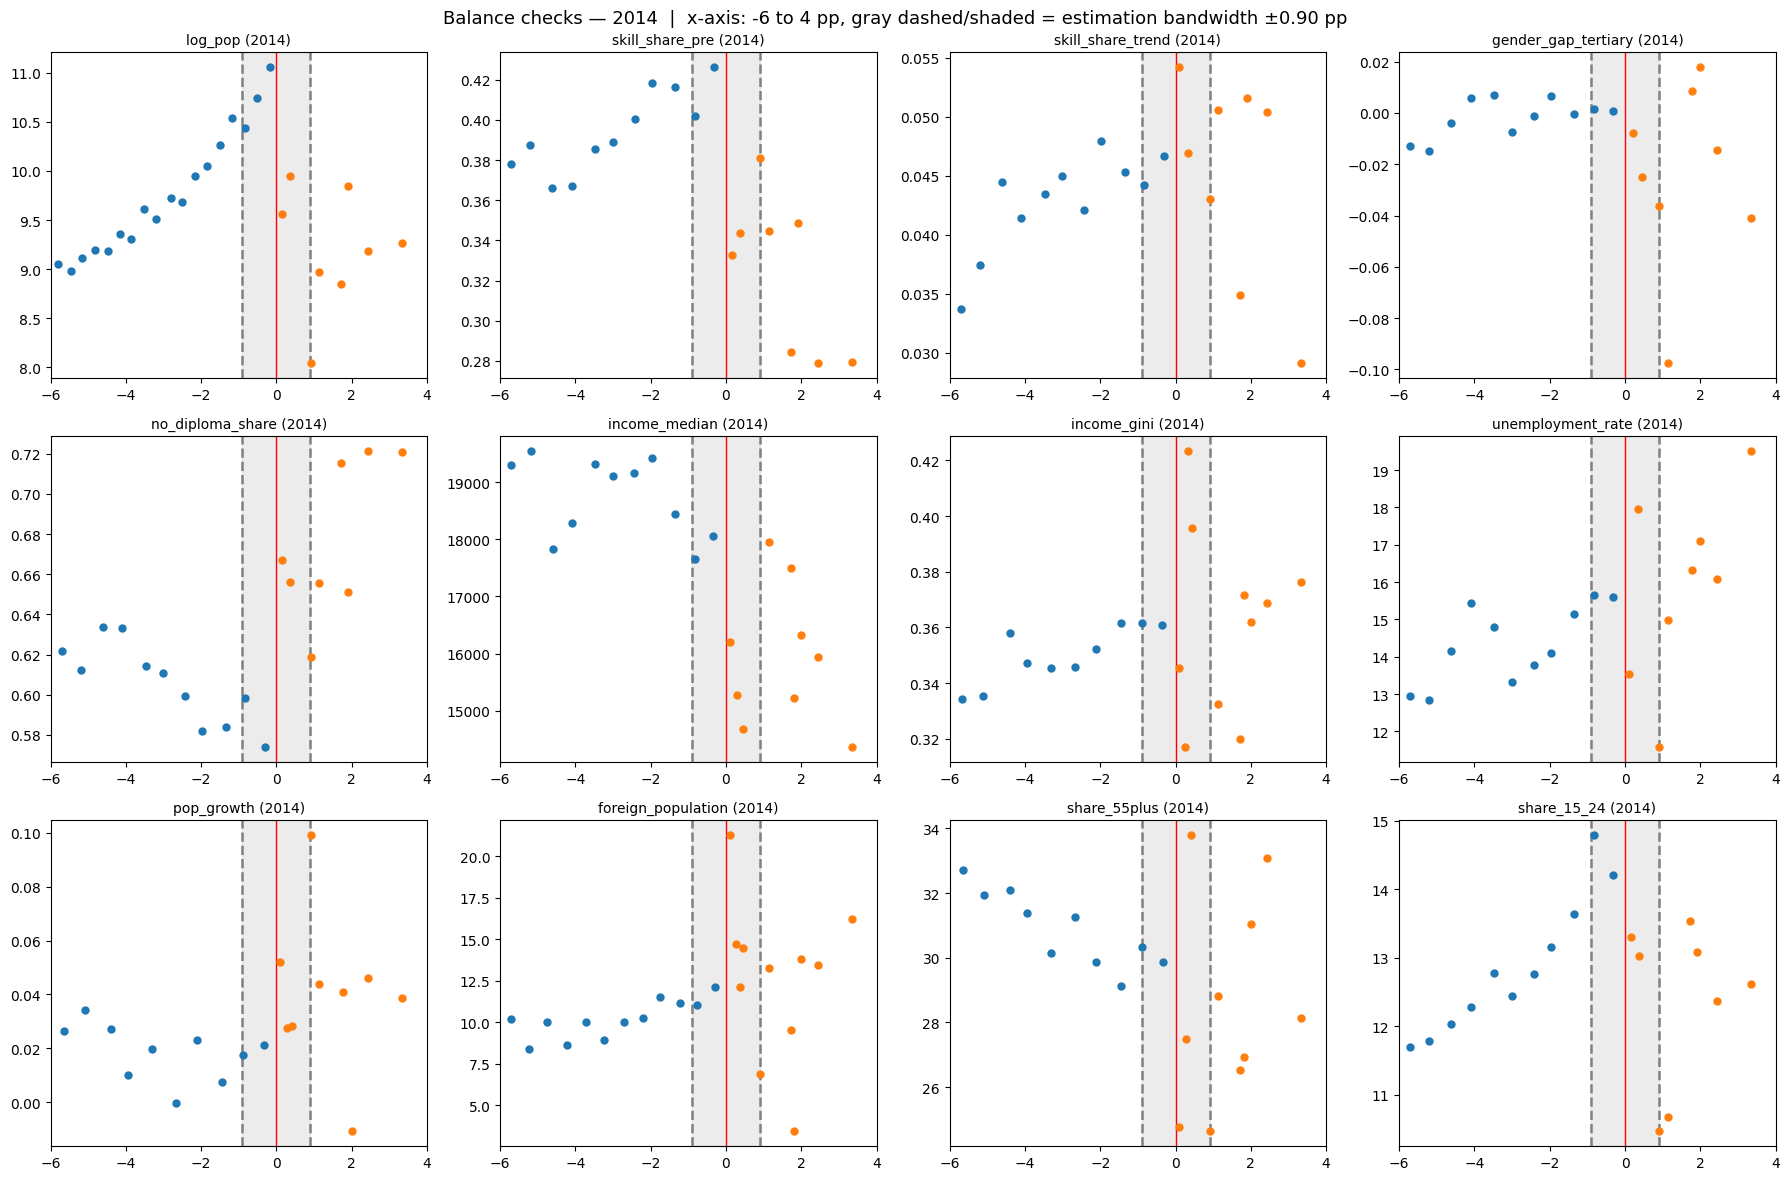

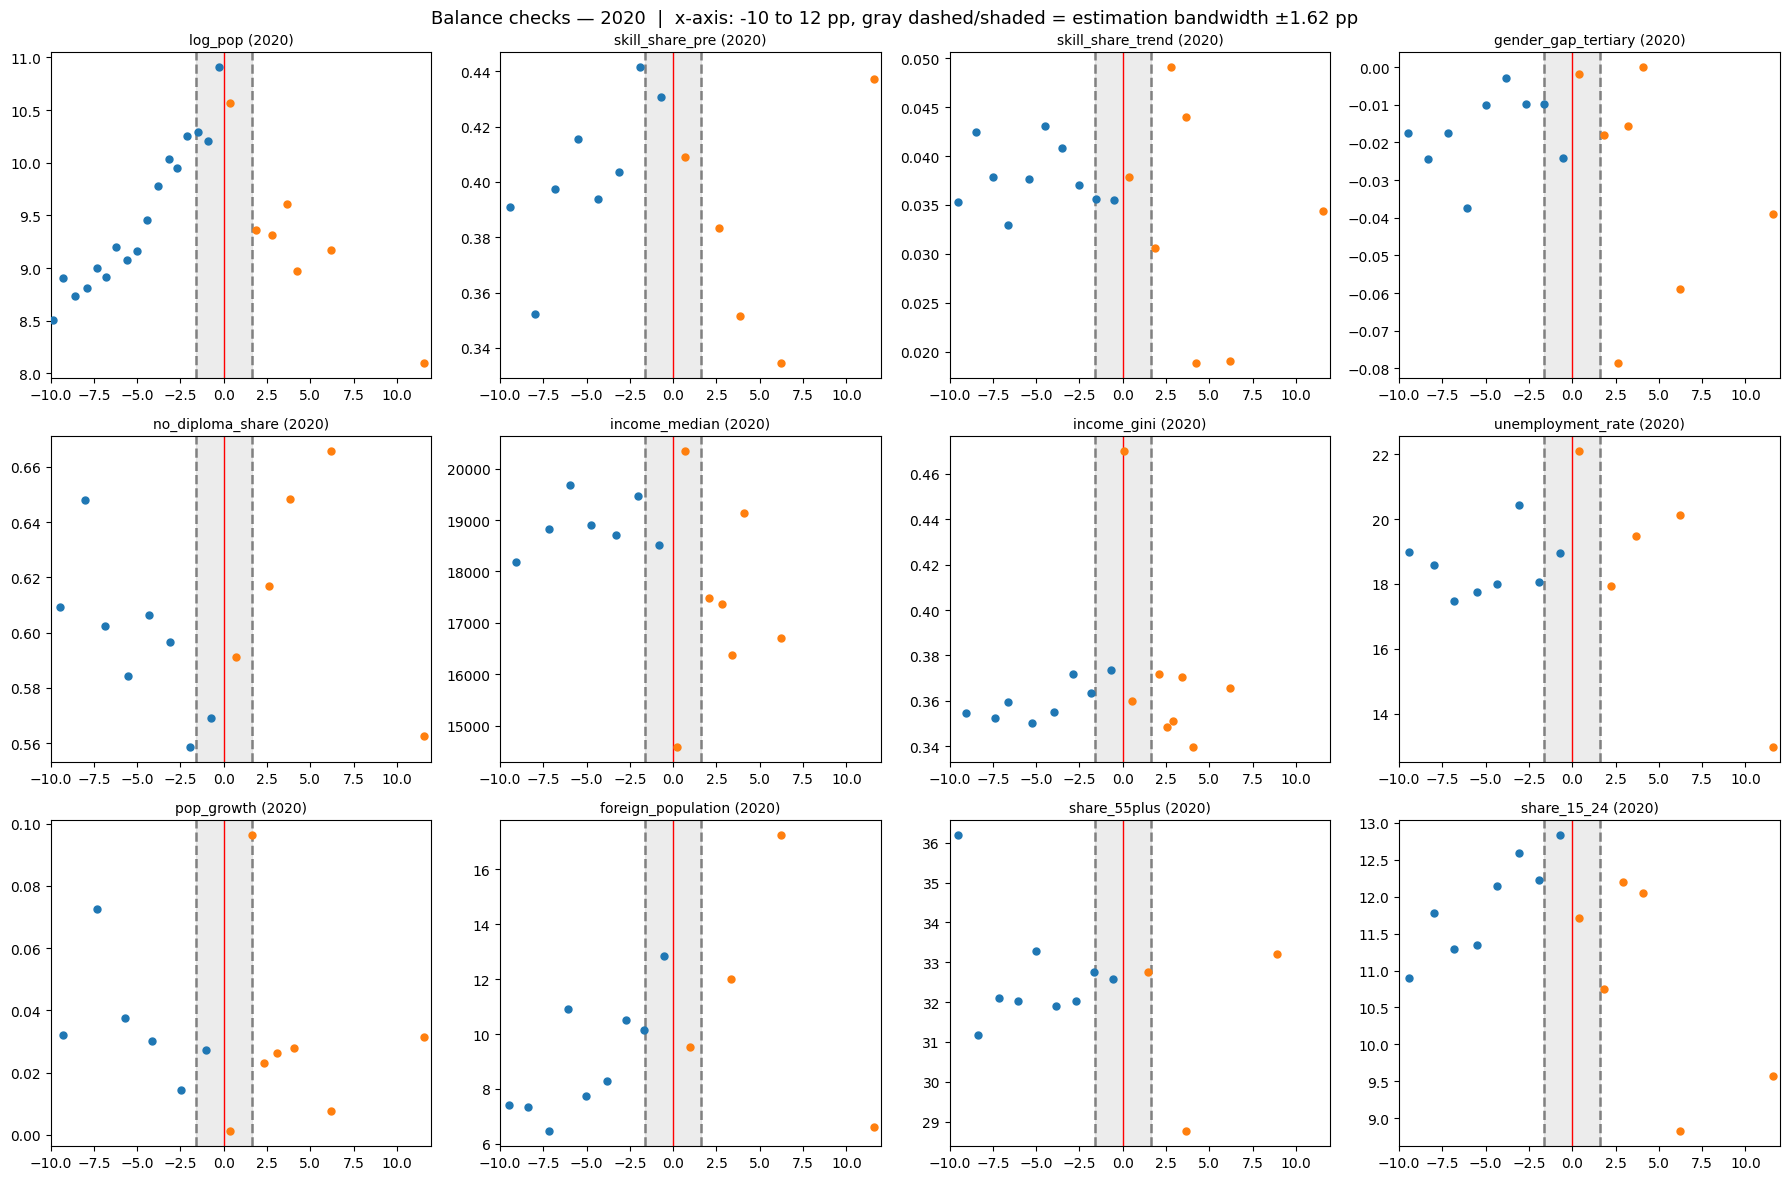

In [24]:
for cycle in [2014, 2020]:
    fig, axes = plt.subplots(3, 4, figsize=(18, 12))
    for ax, cov in zip(axes.flat, covariates):
        plot_balance_rdrobust(ax, df_rdd, cov, cycle=cycle,
                              h=bw_by_cycle[cycle], xlim=plot_xlim_by_cycle[cycle])
    lo, hi = plot_xlim_by_cycle[cycle]
    fig.suptitle(f"Balance checks — {cycle}  |  x-axis: {lo} to {hi} pp, "
                 f"gray dashed/shaded = estimation bandwidth ±{bw_by_cycle[cycle]:.2f} pp", fontsize=13)
    plt.tight_layout()
    plt.show()

## McCrary Test

In [25]:
# ── McCrary-style manipulation test on the running variable ──
# rddensity implements the Cattaneo, Jansson & Ma (2018/2020) bias-corrected
# local-polynomial density test — the modern, standard-error-robust version
# of the original McCrary (2008) test.


# Run separately by cycle (2014, 2020): manipulation incentives, list registration
# rules, and vote-counting differ by election, so pooling would obscure a
# discontinuity that's real in only one cycle. 2008 is excluded — no observations
# above the cutoff means there is nothing to test for a jump against.
for cycle in [2014, 2020]:
    sub = df_rdd.loc[df_rdd['election_year'] == cycle, 'd_50'].dropna()

    dens = rddensity(X=sub, c=0)  # c=0: cutoff of d_50, as in the main design

    # p_jk = jackknife p-value for H0: density is continuous at the cutoff.
    # p_jk > 0.10 (conventional threshold) => no evidence of manipulation/sorting.
    p_val = dens.test.loc['p_jk']
    print(f"McCrary density test ({cycle}): p = {p_val:.3f} "
          f"({'no evidence of manipulation' if p_val > 0.10 else 'possible manipulation — investigate'})")

    # Visual check: plots the estimated density on each side of the cutoff.
    # A visible jump at d_50 = 0 is the graphical analogue of a low p-value.
    rdplotdensity(dens, sub, title=f"Density of d_50 — {cycle}")

McCrary density test (2014): p = 0.079 (possible manipulation — investigate)
McCrary density test (2020): p = 0.000 (possible manipulation — investigate)


Density test fails in both election periods:

- **Mechanical asymmetry**: close far-right wins are just intrinsically rarer than close losses in this setting (e.g., because far-right lists are rarely the largest list, so barely winning the plurality is a rarer event than barely losing it) — this is a structural feature of French multi-list plurality elections, not manipulation.
- **True local sorting**: something specifically happens right at d_50=0 that doesn't happen at d_50=-0.3 or +0.3 — more consistent with actual manipulation (vote-count adjustment, contested results, etc.).


As Diff-in-Disc does not require this sharp RDD randomization at the cutoff. 

In [26]:
# ── Diagnose asymmetry driving a failed density test ──
# Rather than tweaking bandwidth/threshold to force p > 0.05 (specification
# searching), report the raw near-cutoff counts: this tells you whether the
# failure is "narrow wins are just rare" (mechanical) vs. a sharp local jump
# right at zero (more consistent with sorting).
for cycle in [2014, 2020]:
    sub = df_rdd.loc[df_rdd['election_year'] == cycle, 'd_50'].dropna()
    n_left  = ((sub > -0.5) & (sub < 0)).sum()   # narrow losses
    n_right = ((sub >= 0)   & (sub < 0.5)).sum() # narrow wins
    print(f"{cycle}: narrow losses (-0.5,0)={n_left}, narrow wins [0,0.5)={n_right}, "
          f"total treated={(sub > 0).sum()}, total control={(sub <= 0).sum()}")

# ── Placebo density test: same test, run on the running variable of the
# PRIOR election cycle for the same communes (t-1 placebo). If the
# discontinuity/asymmetry already existed before treatment could have acted,
# it's a stable structural feature of the setting -- consistent with the
# Diff-in-Disc identifying assumption (Grembi, Nannicini & Troiano 2016) --
# rather than manipulation triggered by treatment itself.
# NOTE: requires a lagged d_50 column (e.g. 'd_50_lag') merged in beforehand.
if 'd_50_lag' in df_rdd.columns:
    for cycle in [2014, 2020]:
        sub_lag = df_rdd.loc[df_rdd['election_year'] == cycle, 'd_50_lag'].dropna()
        dens_lag = rddensity(X=sub_lag, c=0)
        p_lag = dens_lag.test.loc['p_jk']
        print(f"Placebo density test, t-1 margin ({cycle}): p = {p_lag:.3f}")

2014: narrow losses (-0.5,0)=19, narrow wins [0,0.5)=6, total treated=13, total control=500
2020: narrow losses (-0.5,0)=7, narrow wins [0,0.5)=2, total treated=13, total control=272
